<a href="https://colab.research.google.com/github/SRXKaiser/analitica-de-datos/blob/main/Practicas%20U3/Victor/ArbolDesicion_23111511.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis de calificaciones de videojuegos

**Alumno:** Victor Manuel Landeros Ramirez  
**Número de control:** 23111511  
**Materia:** Analítica de Datos

## Objetivo

Comparar dos maneras de analizar el Metascore de un videojuego a partir de su plataforma y año de lanzamiento. La regresión lineal estima una puntuación y el árbol de decisión clasifica la puntuación como baja, media o alta.

## 1. Carga y exploración de los datos

El archivo `BestVideoGamesofAllTime.csv` contiene el título, la posición en el ranking, el Metascore, la plataforma y la fecha de lanzamiento. Un título puede aparecer en varias plataformas, así que cada fila se interpreta como un registro del videojuego en una plataforma.

In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
ruta = '/content/drive/MyDrive/ColabNotebooks/BestVideoGamesofAllTime.csv'

df = pd.read_csv(
    ruta,
    sep=None,
    engine='python'
)

df.head(10)

,Game,Ranking,Metascore,Platform,Release Date
0,The Legend of Zelda: Ocarina of Time,1,99,Nintendo 64,"November 23, 1998"
1,Tony Hawk's Pro Skater 2,2,98,PlayStation,"September 20, 2000"
2,Grand Theft Auto IV,3,98,PlayStation 3,"April 29, 2008"
3,SoulCalibur,4,98,Dreamcast,"September 8, 1999"
4,Grand Theft Auto IV,5,98,Xbox 360,"April 29, 2008"
5,Super Mario Galaxy,6,97,Wii,"November 12, 2007"
6,Super Mario Galaxy 2,7,97,Wii,"May 23, 2010"
7,Red Dead Redemption 2,8,97,Xbox One,"October 26, 2018"
8,Grand Theft Auto V,9,97,Xbox One,"November 18, 2014"
9,Grand Theft Auto V,10,97,PlayStation 3,"September 17, 2013"


In [3]:
print("Cantidad de filas:", df.shape[0])
print("Cantidad de columnas:", df.shape[1])

print("\nColumnas del dataset:")
print(df.columns.tolist())

Cantidad de filas: 19106
Cantidad de columnas: 5

Columnas del dataset:
['Game', 'Ranking', 'Metascore', 'Platform', 'Release Date']


In [4]:
print(df.shape)
print(df.dtypes)
print(df.isnull().sum())
print(df.duplicated().sum())

(19106, 5)
Game            object
Ranking          int64
Metascore        int64
Platform        object
Release Date    object
dtype: object
Game            0
Ranking         0
Metascore       0
Platform        0
Release Date    0
dtype: int64
0


In [5]:
df.describe()

,Ranking,Metascore
count,19106.000000,19106.000000
mean,9553.500000,70.577620
std,5515.571457,12.268896
min,1.000000,11.000000
25%,4777.250000,64.000000
50%,9553.500000,72.000000
75%,14329.750000,79.000000
max,19106.000000,99.000000


## 2. Preparación y visualización

Se extrae el año de la fecha de lanzamiento. El histograma muestra cómo se distribuyen las calificaciones. El diagrama de dispersión y el mapa de calor permiten explorar la relación entre las variables numéricas.

El ranking se usa en la exploración. Su relación con el Metascore podría anticipar la respuesta y dar una evaluación demasiado optimista si se incluyera en los modelos.

In [6]:
sns.set_theme(style="whitegrid")

# Convertir la fecha a formato de fecha
df["Release Date"] = pd.to_datetime(
    df["Release Date"].astype(str).str.strip(),
    errors="coerce"
)

# Crear columna con el año de lanzamiento
df["Year"] = df["Release Date"].dt.year

display(df.head())

,Game,Ranking,Metascore,Platform,Release Date,Year
0,The Legend of Zelda: Ocarina of Time,1,99,Nintendo 64,1998-11-23,1998
1,Tony Hawk's Pro Skater 2,2,98,PlayStation,2000-09-20,2000
2,Grand Theft Auto IV,3,98,PlayStation 3,2008-04-29,2008
3,SoulCalibur,4,98,Dreamcast,1999-09-08,1999
4,Grand Theft Auto IV,5,98,Xbox 360,2008-04-29,2008


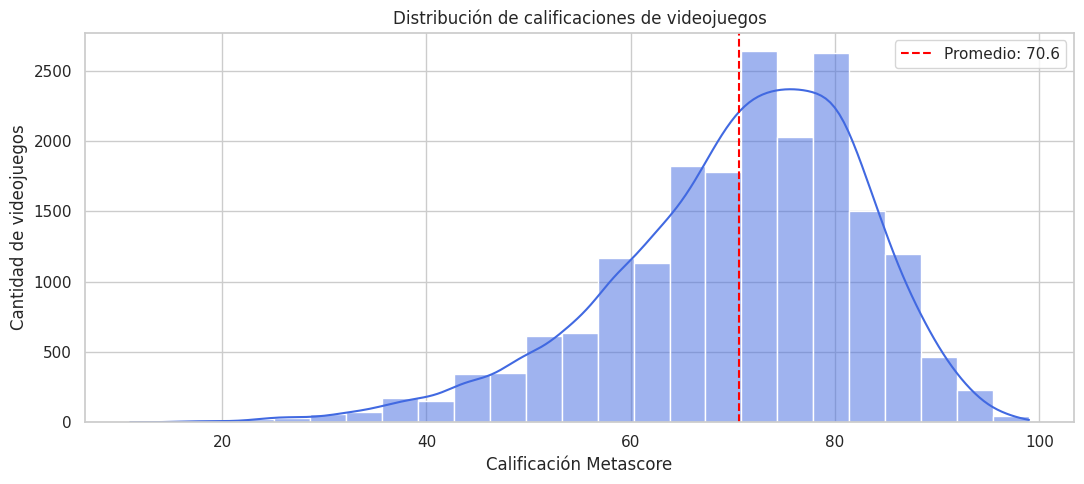

In [7]:

plt.figure(figsize=(11, 5))

sns.histplot(
    data=df,
    x="Metascore",
    bins=25,
    kde=True,
    color="royalblue",
    edgecolor="white"
)

plt.axvline(
    df["Metascore"].mean(),
    color="red",
    linestyle="--",
    label=f'Promedio: {df["Metascore"].mean():.1f}'
)

plt.title("Distribución de calificaciones de videojuegos")
plt.xlabel("Calificación Metascore")
plt.ylabel("Cantidad de videojuegos")
plt.legend()
plt.tight_layout()
plt.show()


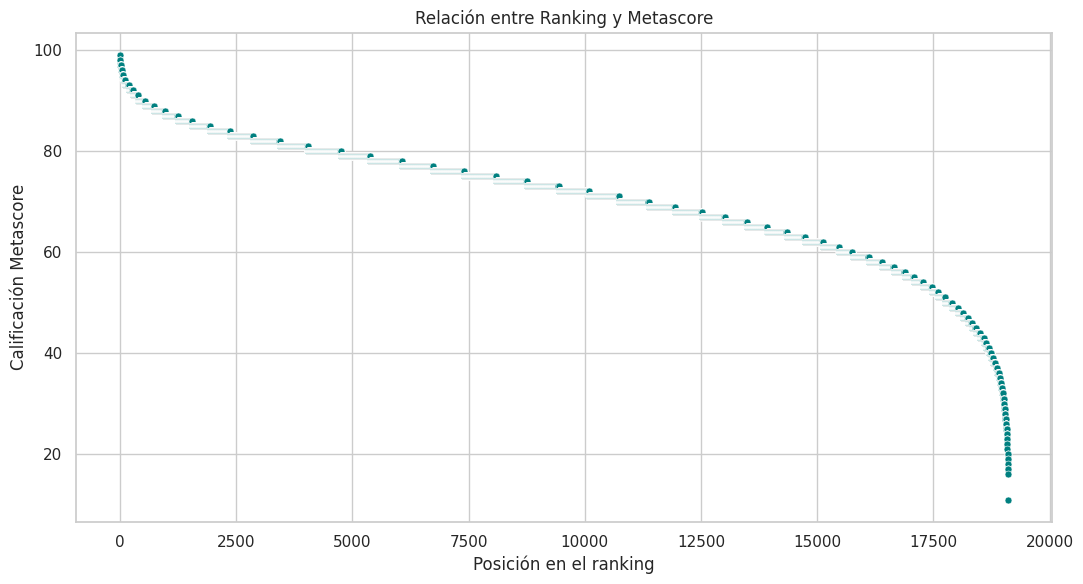

In [8]:

plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=df,
    x="Ranking",
    y="Metascore",
    alpha=1,
    s=25,
    color="teal"
)

plt.title("Relación entre Ranking y Metascore")
plt.xlabel("Posición en el ranking")
plt.ylabel("Calificación Metascore")
plt.tight_layout()
plt.show()


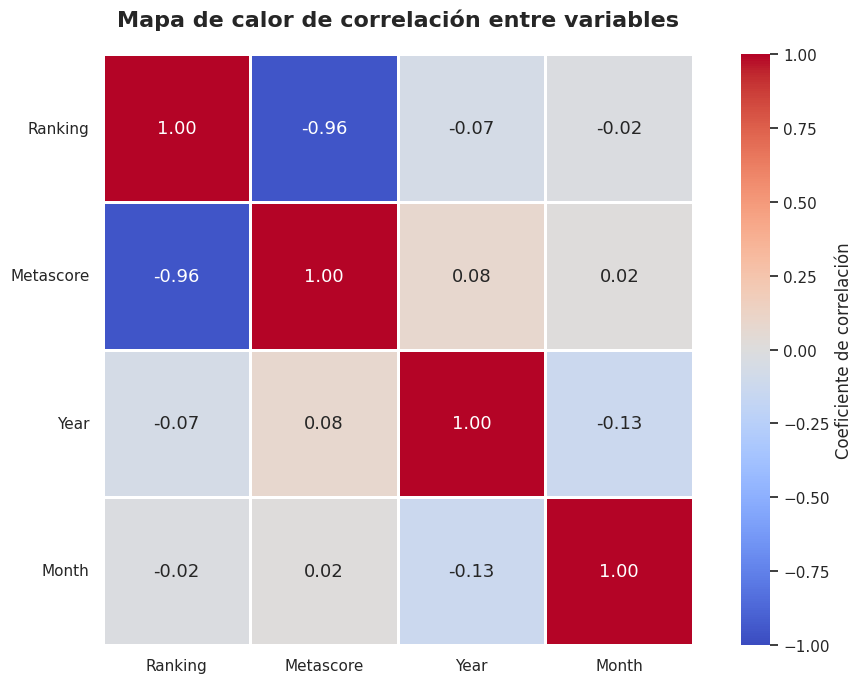

In [9]:

# copia del dataset
datos = df.copy()

# columnas numericas con el tipo correcto
for col in ["Ranking", "Metascore"]:
    datos[col] = pd.to_numeric(datos[col], errors="coerce")

# crear columnas de fecha si no existen
datos["Release Date"] = pd.to_datetime(
    datos["Release Date"],
    errors="coerce"
)

datos["Year"] = datos["Release Date"].dt.year
datos["Month"] = datos["Release Date"].dt.month

columnas = ["Ranking", "Metascore", "Year", "Month"]

# matriz de correlacion
correlacion = datos[columnas].corr()

# mapa de calor
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlacion,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=1,
    linecolor="white",
    square=True,
    annot_kws={"size": 13},
    cbar_kws={"label": "Coeficiente de correlación"}
)

plt.title(
    "Mapa de calor de correlación entre variables",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.xticks(rotation=0, fontsize=11)
plt.yticks(rotation=0, fontsize=11)

plt.tight_layout()
plt.show()


## 3. Regresión lineal

La variable objetivo es `Metascore`. Los predictores son la plataforma y el año. Se usa el 80 % de los registros para entrenar y el 20 % para evaluar. La plataforma se codifica en variables binarias dentro del pipeline, que se ajusta a partir del conjunto de entrenamiento.

Se comparan el MAE, el RMSE y el R² con un modelo base que predice el Metascore promedio del conjunto de entrenamiento.

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

datos_reg = df[["Platform", "Year", "Metascore"]].copy()
datos_reg["Metascore"] = pd.to_numeric(datos_reg["Metascore"], errors="coerce")
datos_reg = datos_reg.dropna(subset=["Platform", "Year", "Metascore"])

X_reg = datos_reg[["Platform", "Year"]]
y_reg = datos_reg["Metascore"]
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=42
)

preprocesador = ColumnTransformer([
    ("plataforma", OneHotEncoder(drop="first", handle_unknown="ignore"), ["Platform"]),
    ("anio", "passthrough", ["Year"]),
])

regresion = make_pipeline(preprocesador, LinearRegression())
base_reg = DummyRegressor(strategy="mean")
regresion.fit(X_reg_train, y_reg_train)
base_reg.fit(X_reg_train, y_reg_train)

resultados_reg = []
for nombre, estimador in [("Regresión lineal", regresion), ("Promedio base", base_reg)]:
    pred_reg = estimador.predict(X_reg_test)
    resultados_reg.append({
        "Modelo": nombre,
        "MAE": mean_absolute_error(y_reg_test, pred_reg),
        "RMSE": np.sqrt(mean_squared_error(y_reg_test, pred_reg)),
        "R²": r2_score(y_reg_test, pred_reg),
    })

metricas_reg = pd.DataFrame(resultados_reg).set_index("Modelo")
display(metricas_reg.round(3))

mae_reg = metricas_reg.loc["Regresión lineal", "MAE"]
mae_base = metricas_reg.loc["Promedio base", "MAE"]
print(f"La regresión se desvía en promedio {mae_reg:.2f} puntos "
      f"del Metascore observado. El error del promedio base es {mae_base:.2f} puntos.")


,MAE,RMSE,R²
Modelo,,,
Regresión lineal,9.240,11.83,0.028
Promedio base,9.413,12.00,-0.000


La regresión se desvía en promedio 9.24 puntos del Metascore observado. El error del promedio base es 9.41 puntos.


## 4. Árbol de decisión

### Preparación, entrenamiento y evaluación

Se crean tres categorías a partir de la puntuación: **Bajo** hasta 59, **Medio** de 60 a 79 y **Alto** de 80 a 100. El árbol aprende usando la plataforma y el año. La división 80/20 conserva las proporciones de las categorías.

Se limita la profundidad a 4 y se piden al menos 100 registros por hoja. La exactitud balanceada da el mismo peso a cada categoría, por lo que complementa la exactitud general cuando hay más juegos de una categoría que de otra.

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)
from sklearn.dummy import DummyClassifier

datos = df.copy()

datos["Metascore"] = pd.to_numeric(
    datos["Metascore"], errors="coerce"
)

# Obtener el año de lanzamiento
if "Year" not in datos.columns:
    fechas = pd.to_datetime(
        datos["Release Date"],
        format="%B %d, %Y",
        errors="coerce"
    )
    datos["Year"] = fechas.dt.year

datos["Year"] = pd.to_numeric(
    datos["Year"], errors="coerce"
)

datos = datos.dropna(
    subset=["Platform", "Year", "Metascore"]
)

# Crear las categorías de calificación
datos["Categoria"] = pd.cut(
    datos["Metascore"],
    bins=[-np.inf, 59, 79, 100],
    labels=["Bajo", "Medio", "Alto"]
)

datos = datos.dropna(subset=["Categoria"])

print("Cantidad de videojuegos por categoría:")
print(datos["Categoria"].value_counts())

# Seleccionar variables
X = datos[["Platform", "Year"]].copy()

# Convertir plataformas a valores numéricos
X = pd.get_dummies(
    X,
    columns=["Platform"],
    dtype=int
)

y = datos["Categoria"]

# Separar entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Crear el arbol de decision
modelo = DecisionTreeClassifier(
    max_depth=4,
    min_samples_leaf=100,
    random_state=42
)

# Entrenar el modelo
modelo.fit(X_train, y_train)

# Realizar predicciones
predicciones = modelo.predict(X_test)

# Evaluar el modelo
print("\nExactitud del modelo:")
print(round(accuracy_score(y_test, predicciones), 4))

print("\nExactitud balanceada:")
print(round(
    balanced_accuracy_score(y_test, predicciones), 4
))

print("\nReporte de clasificación:")
print(classification_report(
    y_test,
    predicciones,
    zero_division=0
))

# Comparacion con un modelo basico
base = DummyClassifier(strategy="most_frequent")
base.fit(X_train, y_train)

print("\nExactitud del modelo básico:")
print(round(base.score(X_test, y_test), 4))


Cantidad de videojuegos por categoría:
Categoria
Medio    11007
Alto      4752
Bajo      3347
Name: count, dtype: int64

Exactitud del modelo:
0.5798

Exactitud balanceada:
0.3404

Reporte de clasificación:
              precision    recall  f1-score   support

        Alto       0.69      0.03      0.05       951
        Bajo       0.00      0.00      0.00       669
       Medio       0.58      1.00      0.73      2202

    accuracy                           0.58      3822
   macro avg       0.42      0.34      0.26      3822
weighted avg       0.51      0.58      0.43      3822


Exactitud del modelo básico:
0.5761


### Visualización del árbol

Cada nodo muestra una regla de decisión y la distribución de categorías en los registros que llegan a ese punto.

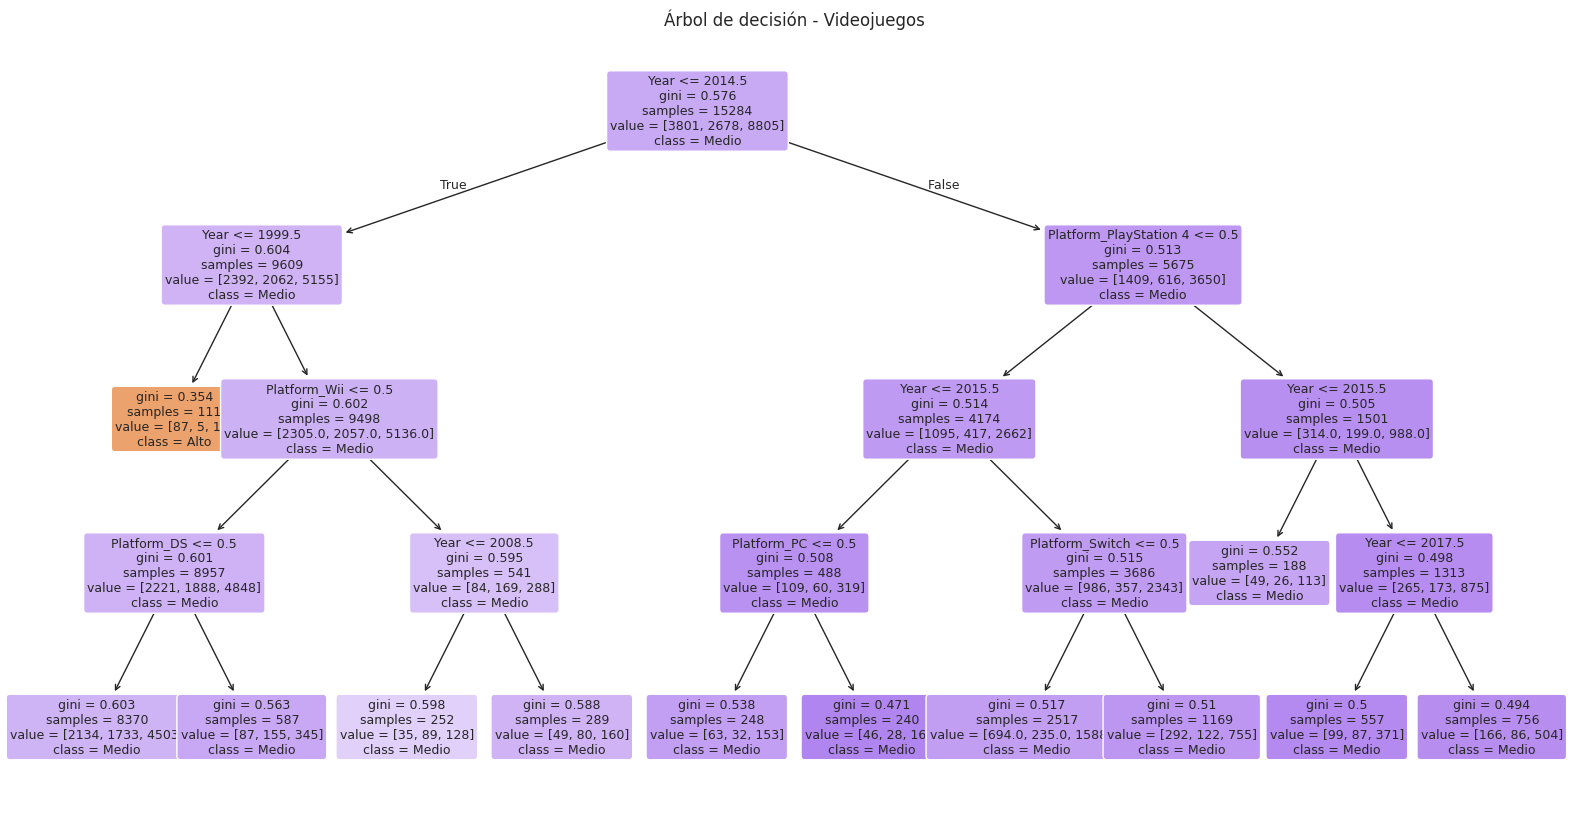

In [12]:
plt.figure(figsize=(20, 10))

plot_tree(
    modelo,
    feature_names=X.columns,
    class_names=list(modelo.classes_),
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Árbol de decisión - Videojuegos")
plt.show()


### Matriz de confusión

Las filas muestran la categoría real y las columnas la categoría que predijo el árbol.

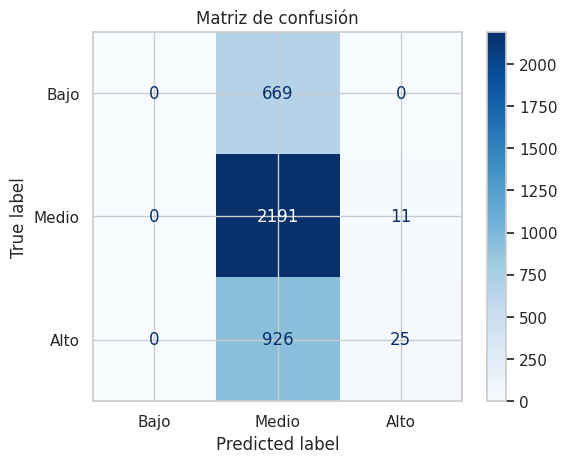

In [13]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    predicciones,
    labels=["Bajo", "Medio", "Alto"],
    cmap="Blues"
)

plt.title("Matriz de confusión")
plt.show()


### Importancia de las variables

Se suman las importancias de las columnas binarias de plataforma para comparar su contribución con la del año. La gráfica describe cómo el árbol utilizó las variables para dividir los datos.

,Importancia
Plataforma,0.16
Año de lanzamiento,0.84


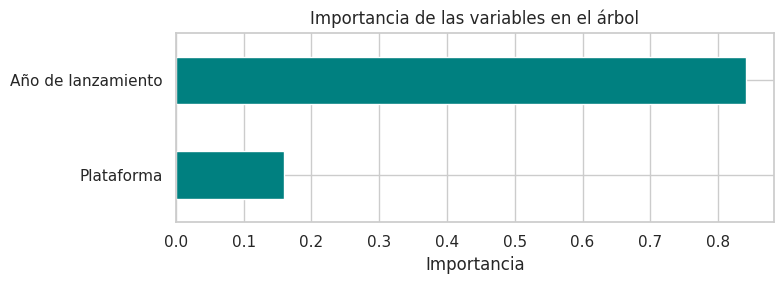

In [14]:
importancias = pd.Series(modelo.feature_importances_, index=X.columns)
importancia_por_variable = pd.Series({
    "Año de lanzamiento": importancias["Year"],
    "Plataforma": importancias.drop("Year").sum(),
}).sort_values()

display(importancia_por_variable.rename("Importancia").round(3))
ax = importancia_por_variable.plot.barh(figsize=(8, 3), color="teal")
ax.set_title("Importancia de las variables en el árbol")
ax.set_xlabel("Importancia")
plt.tight_layout()
plt.show()


## 5. Conclusión

En esta práctica analicé el Metascore de dos maneras. Con la regresión lineal busqué estimar la puntuación y usé el MAE para medir cuántos puntos se alejaban las predicciones de los valores reales. Con el árbol de decisión busqué ubicar cada videojuego en una de tres categorías.

El árbol obtuvo una exactitud de **57.98 %**, apenas por encima del **57.61 %** del modelo que siempre predice la categoría más frecuente. Al revisar los resultados por categoría, vi que el árbol acertó casi todos los casos de nivel medio, identificó pocos de nivel alto y dejó sin detectar los de nivel bajo. Eso explica que la exactitud balanceada quedara en **34.04 %**.

Para este conjunto de datos, la plataforma y el año aportaron poca información al árbol para distinguir las tres categorías. También encontré títulos que estan en mas de una plataforma. Los datos estan divididos por filas, así que los resultados describen el desempeño con registros separados al azar. Para ver el desempeño con títulos totalmente nuevos tendría sentido dividirlos por juego.